# LIBS

In [1]:
#| export
import numpy as np 

import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import matplotlib.patches as mpatches
import matplotlib.gridspec as gridspec
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import string


import os
import re
import zipfile
import string
from tqdm.notebook import tqdm
import pandas as pd
pd.options.mode.chained_assignment = None

import pathlib
from scipy.stats import rankdata

from scipy.stats import gaussian_kde


# from git import Repo
# current_branch = Repo('/home/gorka/github/andi_datasets/').active_branch.name
# print(f"andi_datasets is in '{current_branch}' branch")


from andi_datasets.utils_challenge import (run_ensemble_task, error_Ensemble_dataset, load_file_to_df,
                                           multimode_dist, _get_error_bounds, 
                                            error_Ensemble_dataset, error_SingleTraj_dataset, distribution_distance)
import andi_datasets.utils_challenge as andi_utils
from andi_datasets.models_phenom import models_phenom
from andi_datasets.analysis import msd_analysis
from andi_datasets.datasets_phenom import datasets_phenom


PATH = pathlib.Path('data/challenge_phase/')


def load_txt_as_dict(file_path):
    dictionary = {}
    
    with open(file_path, 'r') as file:
        lines = file.readlines()
        
        for line in lines:
            key, value = line.strip().split(': ')
            dictionary[key] = value
    
    return dictionary


#### Params
num_fovs = 30
correct_exps = np.array([2,3,4,6,7,8,9,10,11]) 
groups = [[0, 1, 2], [3], [4], [5, 6], [7], [8]]

order_exps_paper = np.array([3,4,5,1,2,6,7,8,9])-1
groups_paper = [[2, 3, 4], [5, 6]] # from the sheet ([[3, 4, 5], [6, 7]]), but already with the -1

bbox_text = dict(boxstyle="round,pad=0.3", edgecolor="grey", facecolor="white", alpha=0.8)




In [2]:
import numpy as np
from tqdm.notebook import tqdm

c_main = '#2790DB'
c_comp = '#DB403D'
c_comp2 = '#2DBD59'
c_grey = '#a3a3a3'
white = '#FFFFFF'
black = '#000000'

import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Arial'
# plt.rcParams['font.serif'] = ['Times New Roman'] + plt.rcParams['font.serif']

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('custom_cmap', [c_main, c_comp], N=250)  # N is the number of discrete colors
cmap_b = LinearSegmentedColormap.from_list('custom_cmap', [c_main, black], N=250)  # N is the number of discrete colors
cmap_r = LinearSegmentedColormap.from_list('custom_cmap', [c_comp, white], N=250)  # N is the number of discrete colors

# example colors
colors = cmap(np.linspace(0, 1, 10))

golden_ratio = (1 + 5 ** 0.5) / 2  # Approximately 1.618
width = 5
height = width / golden_ratio

def put_label(ax, label):
    ax.text(0, 1.1, label, transform=ax.transAxes,
           fontsize=16, fontweight='bold', va='top', ha='left')

In [3]:
path_folders = '/media/gorka/DATA/andi2_data/datasets_phases_challenge/challenge_phase/'
path_pred = lambda letter, track, exp, fov: path_folders+f'submissions_post15/{letter}/track_{track}/exp_{exp}/fov_{fov}.txt'
path_ref = lambda track, exp, fov: path_folders+f'reference_challenge_phase/track_{track}/exp_{exp}/traj_labs_fov_{fov}.txt'

path_leaderboard = lambda track_str, task_str: path_folders+f'final_leaderboards/Final_leaderboard_{track_str}_{task_str}.csv'

name_metrics_paper_st = [r'RMSE (CP)', 'JSC (CP)', r'MAE ($\alpha$)', r'MSLE ($K$)',r'F$_1$ (diff. type)']
arrow_metrics_st = [r' $ \downarrow$', r' $ \uparrow$',r' $ \downarrow$', r' $ \downarrow$', r' $ \uparrow$']
                    
name_metrics_paper_ens = [r'$W_1 (\alpha)$', r'$W_1 (K)$']
arrow_metrics_ens = [r' $ \downarrow$',r' $ \downarrow$']


## Aux functions

In [4]:
def get_letter_from_teams(teams):
    dict_mapping = load_txt_as_dict(path_folders+'team_mapping.txt')
    dict_inv = dict((v,k) for k,v in dict_mapping.items())
    return [dict_inv[key] for key in teams]

In [11]:
def get_ranking_exp(track, task, exp):
    ''' Given a track, task and experiment, returns a dataframe with the rankings on that particular set.'''

    if task == 1:
        keys = ['RMSE CP', 'JSC CP', 'alpha', 'K', 'state']
    else:
        keys = ['alpha','K']
        
        # There is a bug with the order of the dataframes in the ensemble (somehow there is disorder...). This is the 
        # order how the exps are stored:
        order_corrected = [0,1,4,5,6,7,8,9,10,11,2,3]
        exp = order_corrected[exp]
    
    track_str = 'videos' if track == 1 else 'trajs'
    task_str = 'single' if task == 1 else 'ens'
    df = pd.read_csv(path_folders + f'final_leaderboards/Final_leaderboard_{track_str}_{task_str}.csv')
    teams = df['Team'].values
    
    dict_mapping = load_txt_as_dict(path_folders + 'team_mapping.txt')
    dict_inv = dict((v,k) for k,v in dict_mapping.items())
    letters = [dict_inv[key] for key in teams]    
  
    df_exp = pd.DataFrame(columns=['Team']+keys)
    
    for letter in letters:

        if letter == 'J': # skipping far_naz
            continue
        
        df = pd.read_csv(path_folders + f'scores_post15/df_track_{track}_task_{task}_{letter}.csv')
        df = df[df.Exp == exp]
    
        vals = []
        for key in df_exp.columns:
            if key == 'Team':
                vals.append(letter)
            else:
                vals.append(df[key].values[0])
                
        df_exp.loc[len(df_exp)] = vals

    
    # Compute MRR
    mrr =np.zeros(df_exp.shape[0])
    for key in df_exp.keys()[1:]:
        
        if key == 'JSC CP' or key == 'state':   
            ranking = rankdata(-df_exp[key].values, method = 'min')
        else: 
            ranking = rankdata(df_exp[key].values, method = 'min')
            
        df_exp[key+ ' rank'] = ranking        
        mrr += 1/ranking        
    df_exp['MRR'] = mrr/5
    
    # Rank from MMR
    df_exp['Global Rank'] = rankdata(-df_exp.MRR, method='min')      

    return df_exp

In [6]:
def metrics_with_codition_st(track = 2, letters_teams = None, condition = None, **kwargs_condition):

    # CHECK FOR CP condition
    try:
        if kwargs_condition['num_cp_max'] > 0:
            exps = [x for x in np.arange(12) if x not in [0,1,5,10]]
        else:
            exps = [x for x in np.arange(12) if x not in [0,1,5]]
    except:
        pass

    try:
        if kwargs_condition['exp_single_state']:
            exps = [10]
    except:
        pass

    print(exps)
    
    metrics = np.zeros((len(exps), 5, len(letters_teams))) # no considering faulty_exps
        
    exp_num_trajs = []
    
    for idxe, exp in enumerate(tqdm(exps)):            
            
        for idxt, letter in enumerate(letters_teams):
    
            # Reset pred dataframe
            try:
                del df_pred_exp, df_true_exp
            except:
                pass      
            
            for fov in range(num_fovs):

                # LOADING TRUES
                # if idxt == 0:
                trues_fov = load_file_to_df(path_ref(track, exp, fov)) 
                
                # Extract indices based on condition and filter true_df
                if condition is not None:
                    traj_idx_values = condition(trues_fov, **kwargs_condition)
                else:
                    traj_idx_values = trues_fov.traj_idx.values                        
                
                filtered_trues_fov = trues_fov[trues_fov['traj_idx'].isin(traj_idx_values)]
                filtered_trues_fov['traj_idx'] = np.arange(filtered_trues_fov.shape[0])                    

                # Full experiment dataframe
                try:
                    filtered_trues_fov.traj_idx += df_true_exp.traj_idx.values[-1]+1
                    df_true_exp = pd.concat([df_true_exp, filtered_trues_fov]) 
                except:            
                    df_true_exp = filtered_trues_fov
                        

                # LOADING PREDS
                preds_fov = load_file_to_df(path_pred(letter,track,exp,fov)) 
                
                filtered_preds_fov = preds_fov[preds_fov['traj_idx'].isin(traj_idx_values)]
                filtered_preds_fov['traj_idx'] = np.arange(filtered_preds_fov.shape[0])
    
                try:                
                    filtered_preds_fov.traj_idx += df_pred_exp.traj_idx.values[-1]+1
                    df_pred_exp = pd.concat([df_pred_exp, filtered_preds_fov])
                except:
                    
                    df_pred_exp = filtered_preds_fov

            if df_true_exp.shape[0] == 0:
                continue
    
            rmse_CP_exp, JI, error_alpha_exp, error_D_exp, error_s_exp = error_SingleTraj_dataset(df_pred_exp, 
                                                                                                  df_true_exp, 
                                                                                                  prints = False, disable_tqdm=True);
            metrics[idxe, :, idxt] = rmse_CP_exp, JI, error_alpha_exp, error_D_exp, error_s_exp
            
            # print(exp, letter, fov)
            # print(np.array([rmse_CP_exp, JI, error_alpha_exp, error_D_exp, error_s_exp]).round(2))
    
        exp_num_trajs.append(df_true_exp.shape[0])
            
    # Calculate weighted averages
    metrics = np.average(metrics, weights=exp_num_trajs, axis = 0)
        
    return metrics
        

# Rank figure

### Rankings

In [7]:
def rank_subp(ax_sc_st1, ax_sc_st2):

    df_st = pd.read_csv(path_folders + 'final_leaderboards/Final_leaderboard_trajs_single.csv')[:-1]
    
    props_traj = {'facecolor' : 'w', 'edgecolor' : c_comp2, 'lw' : 1.5}
    
    #### Scatter CP
    ax_sc_st1.scatter(df_st['RMSE (CP) '], df_st['JSC (CP) '], **props_traj)
    plt.setp(ax_sc_st1, xlabel = r'RMSE (CP)', ylabel = r'JSC (CP)')
    
    # making best higher
    ax_sc_st1.invert_xaxis()
    
    #### Scatter Diff props
    ax_sc_st2.scatter(df_st['MAE (alpha) '], np.log(df_st['MSLE (K) ']), **props_traj)
    plt.setp(ax_sc_st2, xlabel = r'MAE ($\alpha$)', ylabel = r'log( MSLE ($K$))')

    # making best higher
    ax_sc_st2.invert_xaxis()
    ax_sc_st2.invert_yaxis()

#### Paper figure

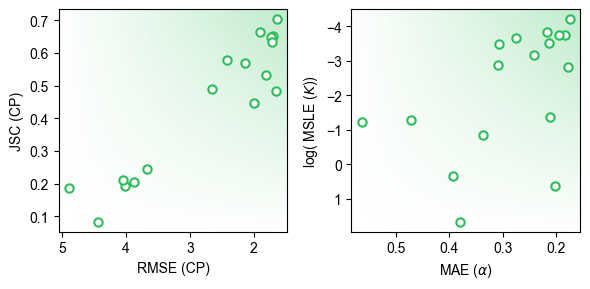

In [8]:
fig = plt.figure(figsize=(2*3, 3), tight_layout = True)


gs = gridspec.GridSpec(1, 2, figure=fig)

ax_sc_st1 = fig.add_subplot(gs[0, 0])
ax_sc_st2 = fig.add_subplot(gs[0, 1])



rank_subp(ax_sc_st1 = ax_sc_st1,
          ax_sc_st2 = ax_sc_st2)



gradient = np.outer(np.linspace(0, 1, 500), np.linspace(0, 1, 500))  # Create 2D gradient
cmap_imshow = LinearSegmentedColormap.from_list('gradient', [(1,1,1), c_comp2])

for ax in [ax_sc_st1, ax_sc_st2]:
    ax.imshow(gradient, extent=[ax.get_xlim()[0], ax.get_xlim()[1], ax.get_ylim()[0], ax.get_ylim()[1]], origin='lower', cmap=cmap_imshow, alpha = 0.3)
    ax.set_aspect('auto')



### Experiments summary

In [12]:
def exp_summary_task(axs, task, num_metrics, colors = None):

    # Position of the panels
    # Task 1: 
    #    order from metrics: RMSE, JSC, MAE, MLSE, F1
    #    wanted order: JSC, RMSE, MLSE, MAE, F1
    if task == 1:
        order_panels = [1, 0, 3, 2, 4]
    # Task 2: same order
    if task == 2:
        order_panels = [0,1]
        

    exps = correct_exps.copy()
    groups = [[0, 1, 2], [3], [4], [5, 6], [7], [8]]

    labels = 'abcde'
    
    
    metrics_track = []
    for track in [1,2]:        
    
        track_str = 'videos' if track == 1 else 'trajs'
        task_str = 'single' if task == 1 else 'ens'
        metrics = []
        for exp in exps:
            df = get_ranking_exp(track = track, task = task, exp = exp)
            # Save dataframe (for Source Data Natcomms)
            # labels_fig = 'a-e' if track == 2 else 'f-g'
            metrics.append(df.iloc[:, 1:6].values)

        metrics = np.array(metrics)
        metrics_track.append(metrics[:,:-1]) # Deleting far_naz from metrics
    
    
    
    name_metrics = df.columns[1:num_metrics+1]
    
    single_state = [10]

    if colors is None:
        colors = cmap(np.linspace(0, 1, len(name_metrics)))
    
    # bracket props
    y = 1.01  # Position above the axis
    bracket_height = 0.02  # The height of the bracket
    lw_br = 1 # bracket line width
    
    for idxm in range(num_metrics):

        title_metric = name_metrics_paper_st[idxm] if task == 1 else name_metrics_paper_ens[idxm]
        title_arrow = arrow_metrics_st[idxm] if task == 1 else arrow_metrics_ens[idxm]
        
        axs[order_panels[idxm]].set_ylabel(title_metric)
    
        # Putting group brackets
        for group in groups_paper:
            # if len(group) == 1:
            #     continue            
            # Start and end positions of the bracket
            x_start, x_end = group[0], group[-1]
            # Draw the horizontal line of the bracket
            axs[order_panels[idxm]].plot([x_start, x_end], [y, y], color='k', transform=axs[idxm].get_xaxis_transform(), lw = lw_br, clip_on=False)    
            # Draw the vertical "arms" of the bracket
            axs[order_panels[idxm]].plot([x_start, x_start], [y, y - bracket_height], color='k', transform=axs[idxm].get_xaxis_transform(), lw = lw_br, clip_on=False)
            axs[order_panels[idxm]].plot([x_end, x_end], [y, y - bracket_height], color='k', transform=axs[idxm].get_xaxis_transform(), lw = lw_br, clip_on=False)
        
        for idxe, exp in enumerate(exps):
            axs[idxm].axvline(idxe, c='k', alpha = 0.1, zorder = -1)
            
            if exp in single_state and idxm == 0 and task == 1: 
                axs[order_panels[idxm]].axvline(order_exps_paper[idxe], c =c_grey, ls = '--')
                continue
    
            for idxtrack, metrics in enumerate(metrics_track):
    
                metrics_plot = metrics[idxe,:,idxm]
        
                if idxm == 0:
                    metrics_plot = metrics_plot[metrics_plot != 0]

                
                axs[order_panels[idxm]].scatter(np.ones(metrics_plot.shape[0])*order_exps_paper[idxe], metrics_plot, alpha = 0.15, color = colors[idxm], lw = 0,
                                  marker = 's' if idxtrack == 0 else 'o'
                                 )
                # Mean of top5 teams
                axs[order_panels[idxm]].scatter(order_exps_paper[idxe], np.median(metrics_plot[:5]), edgecolor = colors[idxm], facecolor = 'w', lw = 2, zorder = 50,
                                 marker = 's' if idxtrack == 0 else 'o')

        
        
        if title_arrow == r' $ \downarrow$':
            axs[order_panels[idxm]].invert_yaxis()
        
    plt.setp(axs[order_panels[-2]] if task == 1 else axs[order_panels[-1]], yscale = 'log')
    plt.setp(axs, xlabel = 'Experiment', xticks = np.arange(len(exps)), xticklabels = np.arange(len(exps))+1);

#     last_ax = axs[-1]
#     last_ax.annotate(
#     'Better', 
#     xy=(1.2, 0.2), xycoords='axes fraction',  # Arrow tip
#     xytext=(1.2, 0.6), textcoords='axes fraction',  # Arrow base and text position
#     arrowprops=dict(arrowstyle='-|>', lw=1.5),  # Arrow base and text position
#     ha='center', va='center', rotation=0  # Rotate text to align vertically
# )

# plt.savefig('ranks_exp_summary_task1.svg')

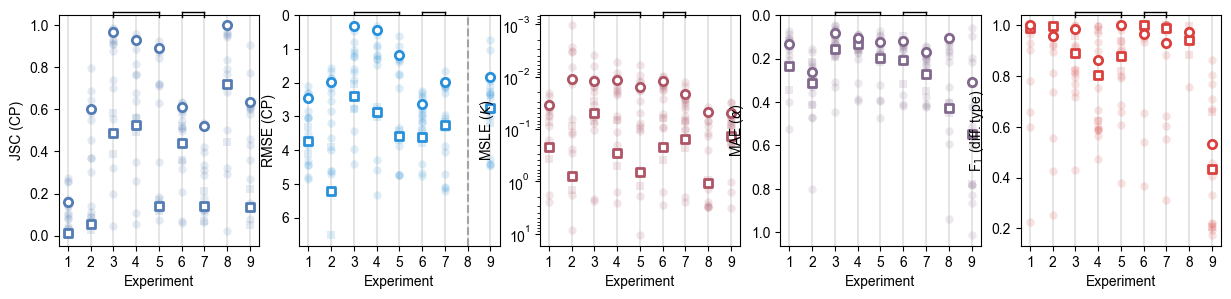

In [13]:
fig, axs = plt.subplots(1, 5, figsize = (5*3, 3))

exp_summary_task(axs, task = 1, num_metrics=5)

# Metrics figure

## Metrics vs CP

In [14]:
def metrics_vs_cp(axs, metrics_to_plot = ['JSC (CP)', 'MSLE (K)', 'MAE (alpha)']): 

    metrics = np.load(path_folders+'analysis_data/metrics_vs_cp.npy')
    df = pd.read_csv(path_leaderboard('trajs', 'single'))
    letters = get_letter_from_teams(df.Team.values)
    
    metric_names = [metric[:-1] for metric in df.columns[2:7]]
    
    
    colors = cmap(np.linspace(0,1,metrics.shape[-1]))

    
    
    for idxm, metric in enumerate(metrics_to_plot):

        vals = []

        idx_metric = np.argwhere(np.array(metric_names) == metric).flatten()[0]
    
        start = 1 if idx_metric == 0 else 0
    
        for idxt in range(metrics.shape[-1]):
            axs[idxm].plot(metrics[start:,idx_metric,idxt], c = colors[idxt], alpha = 1, label = letters[idxt])

            # Add metrics[start:,idx_metric,idxt] as a new column to a DataFrame
            if idxt == 0:
                df_metrics = pd.DataFrame()
            df_metrics[letters[idxt]] = metrics[start:, idx_metric, idxt]

        # For Source Data Natcomms
        # label_fig = 'cde'[idxm]
        # print(df_metrics)
        
        if metric == 'MSLE (K)':
            axs[idxm].set_yscale('log')
            
            
        axs[idxm].set_ylabel(name_metrics_paper_st[idx_metric])
    

    
    plt.setp(axs, xlabel = 'Changepoints per trajectory')



# plt.savefig('figures/metrics_metrics_vs_cp.svg')

Text(0, 0.5, 'MSLE ($D$)')

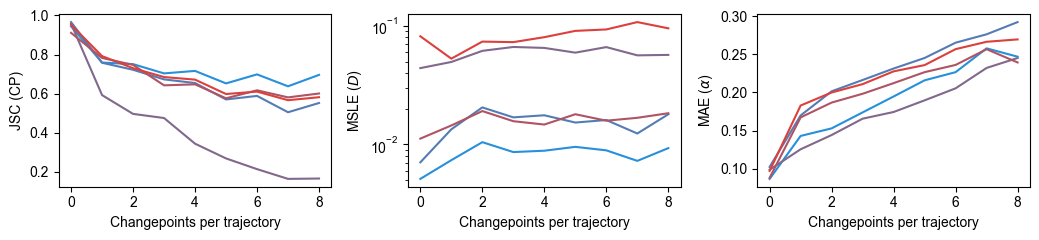

In [15]:
metrics_to_plot = ['JSC (CP)', 'MSLE (K)', 'MAE (alpha)']
fig, axs = plt.subplots(1, len(metrics_to_plot), figsize = (len(metrics_to_plot)*3.5, 2.5), tight_layout = True)
metrics_vs_cp(axs)

axs[1].set_ylabel('MSLE ($D$)')
# plt.setp(axs[:-1], xlabel = '', xticklabels = [])

## Single state

In [18]:
def plot_single_state(axs):

    # order alpha, K
    ax_a = axs[1]
    ax_k = axs[0]
    
    metrics_exp = pd.read_csv('df_single_state.csv')
    
    
    ax_a.scatter(metrics_exp.FPR, metrics_exp.alpha, c = c_comp2, alpha = 0.8, edgecolor = 'k')
    ax_a.axhline(metrics_exp.iloc[-1].alpha, c = 'k', ls = '--', zorder = -1)
    
    ax_k.scatter(metrics_exp.FPR, metrics_exp.K, c = c_comp2, alpha = 0.8, edgecolor = 'k')
    ax_k.axhline(metrics_exp.iloc[-1].K, c = 'k', ls = '--', zorder = -1)
    
    plt.setp(ax_a, ylabel = r'MAE ($\alpha$)', xlabel = 'False Positive Rate');
    plt.setp(ax_k, xlabel = 'False Positive Rate', ylabel = r'MLSE ($K$)');
    
    
    # Create handles for the legend
    circle = mlines.Line2D([], [], color = c_comp2, alpha = 0.8, marker='o', linestyle='None', label='Participant', markeredgecolor = 'k')  # Circle marker
    line = mlines.Line2D([], [], color='k', linestyle='--', label='MSD fit')  # Line
    
    # Add legend to the plot (do it in alpha ax because hides less)    
    ax_a.legend(handles=[circle, line], loc = 'lower right')
    
    plt.setp(axs, yscale = 'log')

# plt.savefig('figures/metrics_single_state.svg')

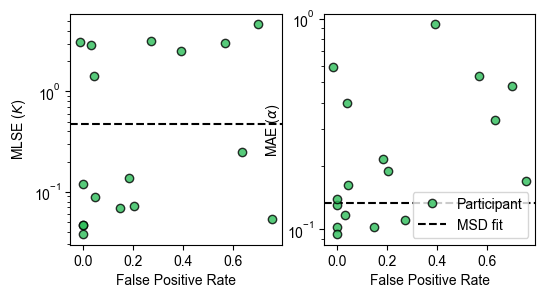

In [20]:
fig, axs = plt.subplots(1, 2, figsize = (3*2, 3))

plot_single_state(axs)


# for i, team in enumerate(mm.Team):
#     axs[0].text(mm.FPR[i], mm.K[i], team, fontsize=12, ha='right', va='bottom')

# for i, team in enumerate(mm.Team):
#     axs[-1].text(mm.FPR[i], mm.alpha[i], team, fontsize=12, ha='right', va='bottom')

## Classification per experiment

In [21]:
tpops = []
ppops = []

track = 2


num_teams = 5
for exp in correct_exps:

    df_ranking = pd.read_csv(path_leaderboard('trajs', 'single')) #get_ranking_exp(track = track, task = task, exp = exp)
    letters = get_letter_from_teams(df_ranking.sort_values(by = 'Global rank').Team.values[:num_teams])
    
    true_state_pops = np.zeros(len(models_phenom().lab_state))
    pred_state_pops = []
    print(exp)
    # for idxt, team in enumerate(df_leaderboard.Team.values[:num_teams]): # Here we are taking top 5 of 
        # letter = dict_inv[team]
    for idxt, letter in enumerate(letters):

        
        state_pops = np.zeros(len(models_phenom().lab_state))
        
        for fov in range(num_fovs):    
            
            preds_fov = load_file_to_df(path_pred(letter,track,exp,fov))   
            
            if idxt == 0:
                trues_fov = load_file_to_df(path_ref(track, exp, fov)) 
            
            
            for idx in range(preds_fov.shape[0]):
    
                # Predicted pop
                cps = np.append(0, preds_fov.changepoints.loc[idx])
                seg_l = cps[1:]-cps[:-1]            
                states = preds_fov.states.loc[idx] 
                for l, s in zip(seg_l, states):
                    state_pops[int(s)] += l
    
                # True pop
                if idxt == 0:
                    # Predicted pop
                    cps = np.append(0, trues_fov.changepoints.loc[idx])
                    seg_l = cps[1:]-cps[:-1]            
                    states = trues_fov.states.loc[idx] 
                    for l, s in zip(seg_l, states):
                        true_state_pops[int(s)] += l
    
        pred_state_pops.append(state_pops)
    tpops.append(true_state_pops)
    ppops.append(pred_state_pops)
#     plt.bar(np.arange(4)+idxt*0.1-0.2, state_pops, width = 0.1)
# plt.bar(np.arange(4), true_state_pops, width = 0.5, facecolor = 'k', alpha = 0.3)
        

2
3
4
6
7
8
9
10
11


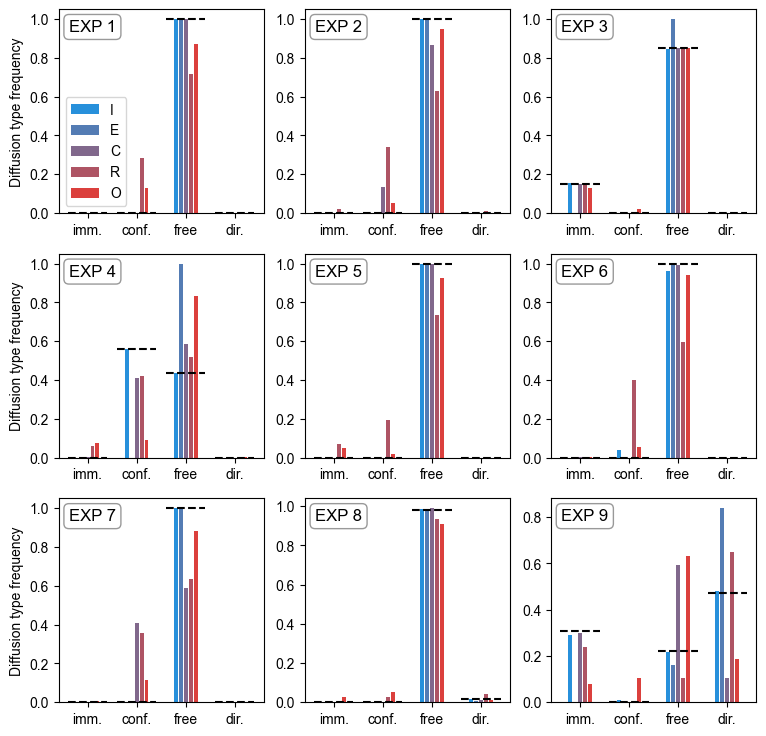

In [ ]:
colors = cmap(np.linspace(0, 1, num_teams))
fig, axs = plt.subplots(3,3, figsize = (3*3, 3*3))

    
for idxe, ax in zip(order_exps_paper.argsort(), axs.flatten()):
     
        
    for idxt, state_pops in enumerate(ppops[idxe]):        
        ax.bar(np.arange(4)+idxt*0.1-(0.1*np.floor(num_teams/2)), state_pops/state_pops.sum(), width = 0.08, facecolor = colors[idxt], label = letters[idxt])
        

    for idxtp, tp in enumerate(tpops[idxe]/tpops[idxe].sum()):
        ax.plot([idxtp-(0.2*np.floor(num_teams/2)), idxtp+(0.2*np.floor(num_teams/2))],
                       [tp, tp],
                       ls = '--', c = 'k')
    ax.text(0.05, 0.95, f'EXP {order_exps_paper[idxe]+1}', transform=ax.transAxes, va='top', ha='left', fontsize = 12,
                       bbox=bbox_text)

axs[0,0].legend(loc = 'lower left')
plt.setp(axs, xticks = np.arange(4), xticklabels = ['imm.', 'conf.', 'free', 'dir.']);
plt.setp(axs[:,0], ylabel = 'Diffusion type frequency')

